# PPO

使用截断代理目标限制策略更新幅度的近端策略优化算法。

## 核心思想

普通 Actor-Critic 如果单次更新幅度过大，新策略的性能可能突然下降。TRPO 通过约束新旧策略之间的差异构造信任区域，但实现较复杂。PPO（Proximal Policy Optimization）使用更容易实现的代理目标近似这一思想。

本 notebook 实现 **PPO-Clip**：用概率比率衡量新旧策略的变化，并通过截断限制过大的策略更新。

## 广义优势估计（GAE）

优势函数衡量动作相对于当前状态平均水平的好坏：

$$
A^\pi(s_t,a_t)=Q^\pi(s_t,a_t)-V^\pi(s_t).
$$

一步 TD 误差为

$$
\delta_t=r_t+\gamma(1-d_t)V(s_{t+1})-V(s_t).
$$

$n$ 步优势估计可写成 TD 误差的加权和：

$$
A_t^{(n)}=\sum_{l=0}^{n-1}\gamma^l\delta_{t+l}.
$$

较小的 $n$ 通常偏差较大、方差较小；较大的 $n$ 则偏差较小、方差较大。GAE 用参数 $\lambda$ 在两者之间权衡：

$$
\hat A_t^{\mathrm{GAE}(\gamma,\lambda)}
=\sum_{l=0}^{T-t-1}(\gamma\lambda)^l\delta_{t+l}.
$$

### PPO-Clip 目标

定义新旧策略对已采样动作的概率比率

$$
r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{\mathrm{old}}}(a_t\mid s_t)}.
$$

PPO-Clip 最大化

$$
L^{\mathrm{clip}}(\theta)=
\mathbb{E}_t\left[
\min\left(
r_t(\theta)\hat A_t,
\operatorname{clip}(r_t(\theta),1-\epsilon,1+\epsilon)\hat A_t
\right)
\right].
$$

截断项会抑制概率比率偏离 $1$ 过多时产生的更新收益。

## 代码实现

### 导入依赖

In [1]:
import gym
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import rl_utils

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


### Actor 与 Critic

Actor 输出离散动作概率；Critic 输出状态价值。

In [2]:
class PolicyNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc2(x), dim=1)


class ValueNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim):
        super(ValueNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.fc2(x)

### PPO-Clip 智能体

实现先根据 TD 误差计算 GAE，并保存更新前策略的动作对数概率；随后复用同一批轨迹训练多个 epoch。每轮通过新旧策略概率比率构造截断代理损失，同时用 TD 目标更新 Critic。

In [4]:
class PPO:
    ''' PPO算法,采用截断方式 '''
    def __init__(self, state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                 lmbda, epochs, eps, gamma, device):
        self.actor = PolicyNet(state_dim, hidden_dim, action_dim).to(device)
        self.critic = ValueNet(state_dim, hidden_dim).to(device)
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(),
                                                lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(),
                                                 lr=critic_lr)
        self.gamma = gamma
        self.lmbda = lmbda # 用来计算优势函数
        self.epochs = epochs  # 一条序列的数据用来训练轮数
        self.eps = eps  # PPO中截断范围的参数
        self.device = device

    def take_action(self, state):
        state = torch.tensor([state], dtype=torch.float).to(self.device)
        probs = self.actor(state)
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()
        return action.item()

    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'],
                              dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions']).view(-1, 1).to(
            self.device)
        rewards = torch.tensor(transition_dict['rewards'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'],
                                   dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'],
                             dtype=torch.float).view(-1, 1).to(self.device)
        # 计算时序差分
        td_target = rewards + self.gamma * self.critic(next_states) * (1 - dones)
        td_delta = td_target - self.critic(states)
        #计算优势函数
        advantage = rl_utils.compute_advantage(self.gamma, self.lmbda,
                                               td_delta.cpu()).to(self.device)
        # 计算log{pi(at|st)}
        old_log_probs = torch.log(self.actor(states).gather(1,
                                                            actions)).detach()
        for _ in range(self.epochs):
            # 与actor-critic不一样的地方，如果是actor-critic就直接是log_probs * advantage
            log_probs = torch.log(self.actor(states).gather(1, actions))
            # ratio计算新策略与旧策略之间的差异:torch.exp(log_probs)/torch.exp(old_log_probs)
            ratio = torch.exp(log_probs - old_log_probs)
            # 通过截断防止新旧策略差异过大时训练奔溃
            surr1 = ratio * advantage
            surr2 = torch.clamp(ratio, 1 - self.eps,
                                1 + self.eps) * advantage  # 截断
            actor_loss = torch.mean(-torch.min(surr1, surr2))  # PPO损失函数
            # 与actor-critic一致
            critic_loss = torch.mean(
                F.mse_loss(self.critic(states), td_target.detach()))
            self.actor_optimizer.zero_grad()
            self.critic_optimizer.zero_grad()
            actor_loss.backward()
            critic_loss.backward()
            self.actor_optimizer.step()
            self.critic_optimizer.step()


In [5]:
actor_lr = 1e-3
critic_lr = 1e-2
num_episodes = 500
hidden_dim = 128
gamma = 0.98
lmbda = 0.95
epochs = 10
eps = 0.2
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

env_name = 'CartPole-v0'
env = gym.make(env_name)
env.seed(0)
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = PPO(state_dim, hidden_dim, action_dim, actor_lr, critic_lr, lmbda,
            epochs, eps, gamma, device)

return_list = rl_utils.train_on_policy_agent(env, agent, num_episodes)

/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/envs/registration.py:592: UserWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.warn(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:329: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:268: DeprecationWarning: WARN: Function `env.seed(seed)` is marked as deprecated and will be re

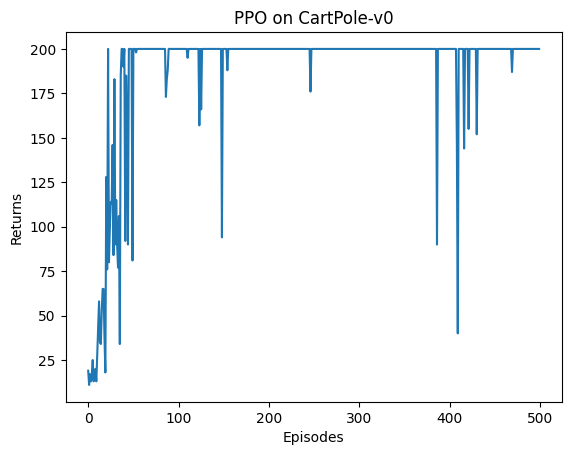

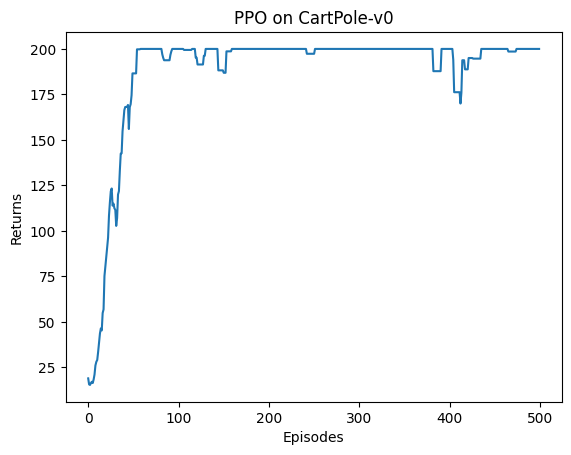

In [6]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('PPO on {}'.format(env_name))
plt.show()

mv_return = rl_utils.moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('PPO on {}'.format(env_name))
plt.show()